# ДЗ 1. Дефекты стальных пластин

Выбрал Steel Plates Faults: здесь небольшая таблица, но семь классов и разные масштабы признаков. Интересно, насколько линейная модель уступит деревьям.

Данные: [UCI Steel Plates Faults](https://archive.ics.uci.edu/dataset/198/steel+plates+faults)

## Гипотезы и критерии проверки

Исходные предположения для экспериментов ниже

1. У константного прогнозща самого частого класса accuracy превысит macro F1 хотя бы на 0.15 из-за дисбаланса
2. Масштабирование улучшит средний CV macro F1 логистической регрессии хотя бы чуть-чуть
3. Подобранный случайный лес обойдёт подобранную логистическую регрессию по CV macro F1 - зависимости могут быть нелинейными
4. У дерева без ограничения глубины разрыв train–CV macro F1 будет больше 0.1 и больше, чем у дерева глубины 5
5. `class_weight='balanced'` улучшит CV macro F1 логистической регрессии хотя бы на сколько-то при одинаковом C=1
6. Отбор 15 признаков через ANOVA снизит CV macro F1 масштабированной логистической регрессии не больше чем на 0.02 (C=1 в обоих случаях)

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             classification_report, ConfusionMatrixDisplay)

SEED = 42
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': False})
print('Python:', sys.version.split()[0], 'sklearn:', sklearn.__version__)

names = Path('data/Faults27x7_var').read_text().splitlines()
data = pd.read_csv('data/Faults.NNA', sep=r'\s+', header=None, names=names)
classes = names[27:]

print('Размер:', data.shape, 'Пропуски:', data.isna().sum().sum())
print('Полные дубликаты:', data.duplicated().sum())

data = data.drop_duplicates().reset_index(drop=True)
X = data[names[:27]]
y = data[classes].idxmax(axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print('Train / test:', len(X_train), len(X_test))

Python: 3.12.11 sklearn: 1.7.2
Размер: (1941, 34) Пропуски: 0
Полные дубликаты: 0
Train / test: 1455 486


## Что видно в данных

Подробный EDA делвю на train. Числа в таблице - измерения и уже рассчитанные индексы. Тип стали представлен двумя бинарными столбцами, поэтому дополнительное кодирование категорий не требуется. Импутация и масштабирование будут внутри пайлайна: параметры считаются заново на каждом обучающем фолде

,count,mean,std,min,25%,50%,75%,max
X_Minimum,1455.0,567.15,518.84,0.00,51.00,408.00,1054.50,1705.00
X_Maximum,1455.0,615.00,495.68,4.00,193.00,446.00,1077.00,1713.00
Y_Minimum,1455.0,1677637.57,1833385.32,6712.00,470122.00,1206989.00,2184898.50,12987661.00
Y_Maximum,1455.0,1677683.01,1833383.66,6724.00,470152.00,1207040.00,2184934.50,12987692.00
Pixels_Areas,1455.0,1899.59,4048.45,2.00,86.00,171.00,861.50,37334.00
X_Perimeter,1455.0,109.44,194.63,2.00,15.00,26.00,86.50,1275.00
Y_Perimeter,1455.0,75.69,120.71,1.00,13.00,25.00,83.00,903.00
Sum_of_Luminosity,1455.0,210003.52,463811.44,255.00,9657.00,19118.00,84545.50,3918209.00
Minimum_of_Luminosity,1455.0,84.14,32.44,0.00,61.00,90.00,106.00,203.00
Maximum_of_Luminosity,1455.0,130.11,19.05,37.00,124.00,127.00,140.00,253.00


,count,share
Other_Faults,505,0.347079
Bumps,301,0.206873
K_Scatch,293,0.201375
Z_Scratch,142,0.097595
Pastry,119,0.081787
Stains,54,0.037113
Dirtiness,41,0.028179


Пропуски train: 0
Постоянные признаки: []


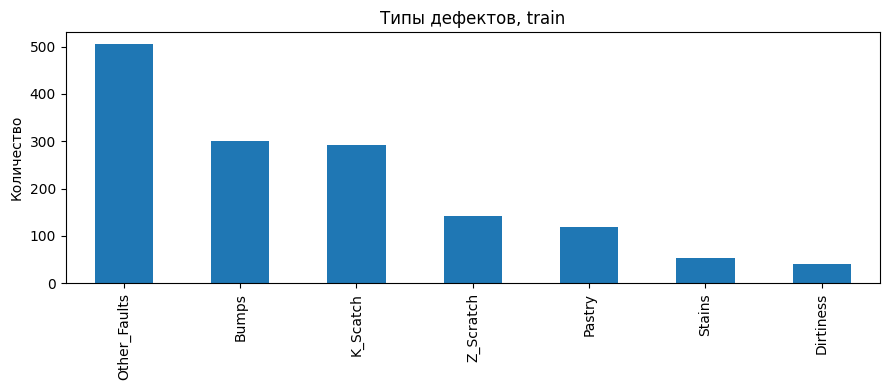

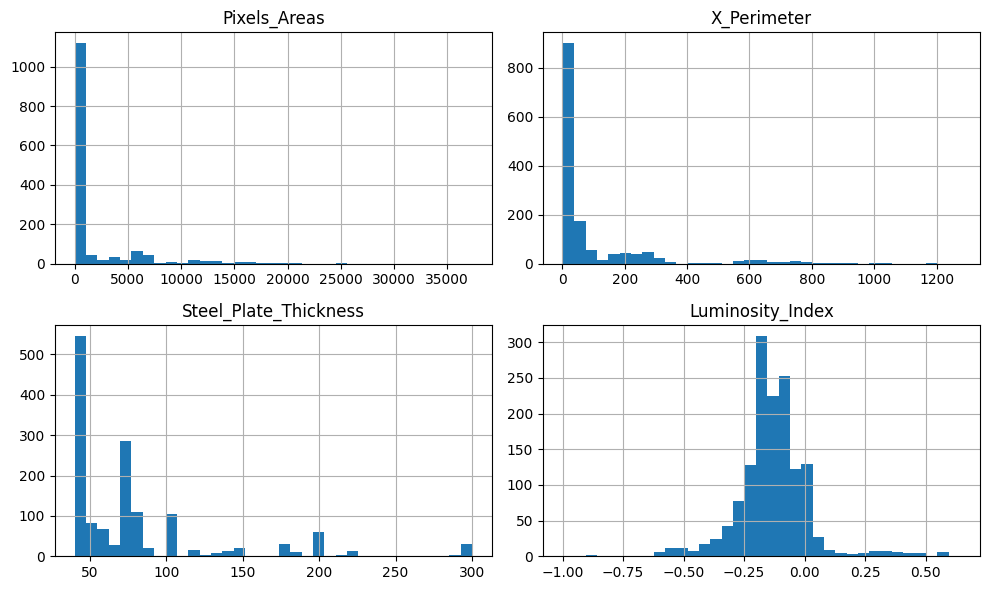

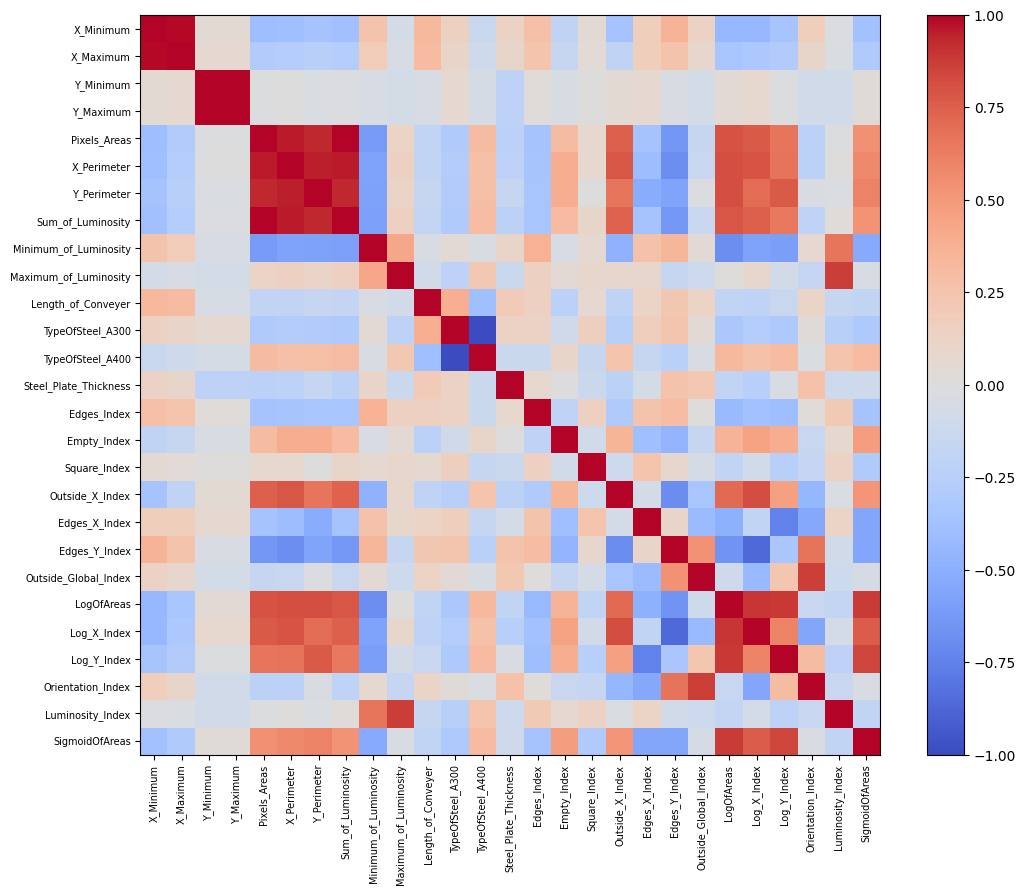

,,correlation
TypeOfSteel_A300,TypeOfSteel_A400,-1.000000
Pixels_Areas,Y_Perimeter,0.932932
Y_Perimeter,Sum_of_Luminosity,0.934173
X_Perimeter,Y_Perimeter,0.951148
Pixels_Areas,X_Perimeter,0.959598
X_Perimeter,Sum_of_Luminosity,0.960510
X_Minimum,X_Maximum,0.987216
Pixels_Areas,Sum_of_Luminosity,0.996573
Y_Minimum,Y_Maximum,1.000000


In [2]:
display(X_train.describe().T.round(2))
display(pd.DataFrame({'count': y_train.value_counts(),
                      'share': y_train.value_counts(normalize=True)}))

print('Пропуски train:', X_train.isna().sum().sum())
print('Постоянные признаки:', X_train.columns[X_train.nunique() <= 1].tolist())

y_train.value_counts().plot.bar(title='Типы дефектов, train')
plt.ylabel('Количество'); plt.tight_layout(); plt.show()

X_train[['Pixels_Areas', 'X_Perimeter', 'Steel_Plate_Thickness', 'Luminosity_Index']].hist(bins=35, figsize=(10, 6))
plt.tight_layout(); plt.show()

corr = X_train.corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=7)
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
display(pairs[pairs.abs() > 0.9].sort_values().rename('correlation').to_frame())

Размеры и периметры имеют длинные правые хвосты; линейной модели будет непросто описать всё одной границей. Есть сильно связанные измерения, в том числе координаты и признаки размера. Их связь сама по себе не доказывает, что удаление улучшит прогноз. Проверю более простой вариант сокращения признаков - ANOVA внутри пацпдапйна

Идентификаторов пластин и времени в таблице нет. Использую стратифицированное случайное разбиение; оценку переноса на новую производственную линию такой эксперимент не даёт

In [ ]:
def log_model(scale=True, balanced=False, select=False):
    steps = [('fill', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scale', StandardScaler()))
    if select:
        steps.append(('select', SelectKBest(f_classif, k=15)))
    steps.append(('model', LogisticRegression(C=1, solver='liblinear',
        max_iter=5000, class_weight='balanced' if balanced else None,
        random_state=SEED)))

    from sklearn.multiclass import OneVsRestClassifier
    steps[-1] = ('model', OneVsRestClassifier(steps[-1][1]))
    return Pipeline(steps)

scoring = {'f1': 'f1_macro', 'accuracy': 'accuracy', 'balanced': 'balanced_accuracy'}
models = {
    'dummy': DummyClassifier(strategy='most_frequent'),
    'log_raw': log_model(scale=False),
    'log_scaled': log_model(),
    'log_balanced': log_model(balanced=True),
    'log_15': log_model(select=True),
    'tree_5': DecisionTreeClassifier(max_depth=5, random_state=SEED),
    'tree_full': DecisionTreeClassifier(random_state=SEED),
}
cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring,
                            return_train_score=True, n_jobs=1)
    cv_rows.append({'model': name, 'cv_f1': scores['test_f1'].mean(),
        'std_f1': scores['test_f1'].std(ddof=1),
        'train_f1': scores['train_f1'].mean(),
        'accuracy': scores['test_accuracy'].mean(),
        'balanced_accuracy': scores['test_balanced'].mean()})
cv_table = pd.DataFrame(cv_rows).set_index('model')
display(cv_table.round(4))

,cv_f1,std_f1,train_f1,accuracy,balanced_accuracy
model,,,,,
dummy,0.0736,0.0000,0.0736,0.3471,0.1429
log_raw,0.3516,0.0110,0.3599,0.5340,0.3881
log_scaled,0.7018,0.0396,0.7333,0.7086,0.6896
log_balanced,0.6691,0.0113,0.6897,0.6687,0.7530
log_15,0.5593,0.0404,0.5646,0.6261,0.5556
tree_5,0.5300,0.0276,0.5618,0.6275,0.5550
tree_full,0.7144,0.0114,1.0000,0.7052,0.7210


## Подбор моделей

Для всех кандидатов одинаковые пять фолдов. Логистической регрессии подбираю C и веса классов, дереву глубину и минимальный лист, лесу число признаков на разбиении. Лучший вариант выбирается только по CV macro F1. Разброс по фолдам буду считать ориентиром устойчивости

In [4]:
searches = {
    'logreg': GridSearchCV(log_model(), {
        'model__estimator__C': [0.01, 0.1, 1, 10],
        'model__estimator__class_weight': [None, 'balanced']},
        scoring='f1_macro', cv=cv, n_jobs=1),
    'tree': GridSearchCV(DecisionTreeClassifier(random_state=SEED), {
        'max_depth': [3, 5, 10, None], 'min_samples_leaf': [1, 5, 15]},
        scoring='f1_macro', cv=cv, n_jobs=1),
    'forest': GridSearchCV(RandomForestClassifier(n_estimators=200,
        random_state=SEED, n_jobs=1), {
        'max_depth': [10, None], 'min_samples_leaf': [1, 3],
        'max_features': ['sqrt', 0.7]}, scoring='f1_macro', cv=cv, n_jobs=1)
}
search_rows = []
for name, search in searches.items():
    search.fit(X_train, y_train)
    search_rows.append({'model': name, 'cv_f1': search.best_score_,
        'std_f1': search.cv_results_['std_test_score'][search.best_index_],
        'params': search.best_params_})
tuning = pd.DataFrame(search_rows).set_index('model')
display(tuning)
winner = tuning.cv_f1.idxmax()
print('Выбрана по CV:', winner)
selected = log_model(select=True).fit(X_train, y_train)
print('Отобранные признаки:', X_train.columns[selected['select'].get_support()].tolist())

,cv_f1,std_f1,params
model,,,
logreg,0.711577,0.040713,"{'model__estimator__C': 10, 'model__estimator_..."
tree,0.737737,0.012586,"{'max_depth': 10, 'min_samples_leaf': 1}"
forest,0.802213,0.024559,"{'max_depth': None, 'max_features': 0.7, 'min_..."


Выбрана по CV: forest
Отобранные признаки: ['X_Minimum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Outside_X_Index', 'Edges_Y_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'SigmoidOfAreas']


## Финальная проверка

Ниже тест для трёх подобранных моделей и константного прогноза

,accuracy,macro_f1,weighted_f1,balanced_accuracy
model,,,,
dummy,0.3457,0.0734,0.1776,0.1429
logreg,0.7305,0.7350,0.7290,0.7169
tree,0.7469,0.7523,0.7492,0.7329
forest,0.7942,0.8038,0.7945,0.7870


              precision    recall  f1-score   support

       Bumps      0.720     0.713     0.716       101
   Dirtiness      0.812     0.929     0.867        14
    K_Scatch      0.978     0.918     0.947        98
Other_Faults      0.708     0.810     0.756       168
      Pastry      0.655     0.487     0.559        39
      Stains      0.933     0.778     0.848        18
   Z_Scratch      1.000     0.875     0.933        48

    accuracy                          0.794       486
   macro avg      0.830     0.787     0.804       486
weighted avg      0.801     0.794     0.795       486



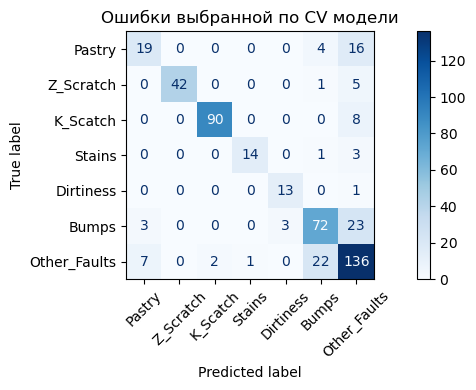

95% bootstrap-интервал macro F1: [0.758 0.841]


In [ ]:
test_rows = []
for name, model in {'dummy': models['dummy'], **{k: v.best_estimator_ for k, v in searches.items()}}.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    test_rows.append({'model': name, 'accuracy': accuracy_score(y_test, pred),
        'macro_f1': f1_score(y_test, pred, average='macro'),
        'weighted_f1': f1_score(y_test, pred, average='weighted'),
        'balanced_accuracy': balanced_accuracy_score(y_test, pred)})

test_table = pd.DataFrame(test_rows).set_index('model')
display(test_table.round(4))

best_model = searches[winner].best_estimator_
pred = best_model.predict(X_test)

print(classification_report(y_test, pred, digits=3, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=classes,
    xticks_rotation=45, cmap='Blues')
plt.title('Ошибки выбранной по CV модели'); plt.tight_layout(); plt.show()


rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
boot = []

for _ in range(1500):
    ix = rng.integers(0, len(yt), len(yt))
    boot.append(f1_score(yt[ix], pred[ix], labels=classes, average='macro', zero_division=0))

print('95% bootstrap-интервал macro F1:', np.quantile(boot, [0.025, 0.975]).round(3))

In [ ]:
raw = cv_table.loc['log_raw', 'cv_f1']
scaled = cv_table.loc['log_scaled', 'cv_f1']
gap_full = cv_table.loc['tree_full', 'train_f1'] - cv_table.loc['tree_full', 'cv_f1']
gap_5 = cv_table.loc['tree_5', 'train_f1'] - cv_table.loc['tree_5', 'cv_f1']

checks = [
    (cv_table.loc['dummy', 'accuracy'] - cv_table.loc['dummy', 'cv_f1'] >= 0.15,
     f"Dummy: accuracy={cv_table.loc['dummy', 'accuracy']:.3f}, macro F1={cv_table.loc['dummy', 'cv_f1']:.3f}. Частый класс даёт заметную accuracy, но остальные классы теряются."),
    (scaled - raw >= 0.02,
     f"Macro F1 без масштаба {raw:.3f}, с масштабом {scaled:.3f}; разница {scaled-raw:+.3f}. Масштаб меняет действие регуляризации на признаки."),
    (tuning.loc['forest', 'cv_f1'] - tuning.loc['logreg', 'cv_f1'] >= 0.03,
     f"Лес {tuning.loc['forest', 'cv_f1']:.3f}, LogReg {tuning.loc['logreg', 'cv_f1']:.3f}. Разница согласуется с пользой нелинейных разбиений, но не доказывает причину."),
    (gap_full > 0.10 and gap_full > gap_5,
     f"Разрыв train–CV: полное дерево {gap_full:.3f}, глубина 5 — {gap_5:.3f}. Запоминание train не равно качеству на новых данных."),
    (cv_table.loc['log_balanced', 'cv_f1'] - scaled >= 0.01,
     f"С весами {cv_table.loc['log_balanced', 'cv_f1']:.3f}, без весов {scaled:.3f}. Взвешивание меняет компромисс ошибок, поэтому улучшение не гарантировано."),
    (cv_table.loc['log_15', 'cv_f1'] >= scaled - 0.02,
     f"15 признаков: {cv_table.loc['log_15', 'cv_f1']:.3f}; все: {scaled:.3f}. ANOVA смотрит на каждый признак отдельно и может потерять полезные совместные связи.")
]

conclusions = []
for i, (ok, explanation) in enumerate(checks, 1):
    line = f"{i}. {'Подтвердилась' if ok else 'Не подтвердилась'} по заданному критерию. {explanation}"
    conclusions.append(line)
    print(line, '\n')

Path('results').mkdir(exist_ok=True)

cv_table.to_csv('results/cv.csv')
tuning.to_csv('results/tuning.csv')
test_table.to_csv('results/test.csv')

Path('results/conclusions.json').write_text(json.dumps({
    'conclusions': conclusions, 'winner': winner,
    'test_macro_f1': float(test_table.loc[winner, 'macro_f1']),
    'bootstrap_interval': np.quantile(boot, [0.025, 0.975]).tolist()
}, ensure_ascii=False, indent=2), encoding='utf-8')

1. Подтвердилась по заданному критерию. Dummy: accuracy=0.347, macro F1=0.074. Частый класс даёт заметную accuracy, но остальные классы теряются. 

2. Подтвердилась по заданному критерию. Macro F1 без масштаба 0.352, с масштабом 0.702; разница +0.350. Масштаб меняет действие регуляризации на признаки. 

3. Подтвердилась по заданному критерию. Лес 0.802, LogReg 0.712. Разница согласуется с пользой нелинейных разбиений, но не доказывает причину. 

4. Подтвердилась по заданному критерию. Разрыв train–CV: полное дерево 0.286, глубина 5 — 0.032. Запоминание train не равно качеству на новых данных. 

5. Не подтвердилась по заданному критерию. С весами 0.669, без весов 0.702. Взвешивание меняет компромисс ошибок, поэтому улучшение не гарантировано. 

6. Не подтвердилась по заданному критерию. 15 признаков: 0.559; все: 0.702. ANOVA смотрит на каждый признак отдельно и может потерять полезные совместные связи. 



1111

## Выводы по гипотезам

1. Подтвердилась по заданному критерию. Dummy: accuracy=0.347, macro F1=0.074. Частый класс даёт заметную accuracy, но остальные классы теряются

2. Подтвердилась по заданному критерию. Macro F1 без масштаба 0.352, с масштабом 0.702, разница +0.35. Масштаб меняет действие регуляризации на признаки

3. Подтвердилась по заданному критерию. Лес 0.802, LogReg 0.712. Разница согласуется с пользой нелинейных разбиений

4. Подтвердилась по заданному критерию. Разрыв train–CV: полное дерево 0.286, глубина 5 - 0.032

5. Не подтвердилась по заданному критерию. С весами 0.669, без весов 0.702, думаю что взвешивание меняет компромисс ошибок поэтому улучшение не гарантировано

6. Не подтвердилась по заданному критерию. 15 признаков: 0.559, все: 0.702ANOVA смотрит на каждый признак отдельно и может потерять полезные совместные связи

У полного дерева разрыв большой, но его CV F1 выше, чем у глубины 5, так что граничение до 5 здесь слишком сильное

Веса классов подняли balanced accuracy с 0.690 до 0.753, но снизили macro F1 с 0.702 до 0.669. То есть средний recall вырос, а баланс precision и recall ухудшился
